# Hourly Temperature Forecasting with a SimpleRNN

I used the Jena Climate measurements to study recurrent forecasting, history length, hidden-state capacity, and backpropagation through time in my Deep Learning coursework.

The model observes a window ending at hour t and predicts temperature at t + 1. I preserve chronological training, validation, and test periods, fit scaling on training observations only, select settings with validation MAE, and compare final test forecasts with persistence.

In [1]:
import json,time,zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error,mean_squared_error
from IPython.display import display
SEED=42;tf.keras.utils.set_random_seed(SEED)
gpus=tf.config.list_physical_devices('GPU');assert gpus,'This cloud run requires a GPU.'
for gpu in gpus:tf.config.experimental.set_memory_growth(gpu,True)
print('TensorFlow:',tf.__version__,'Available GPUs:',len(gpus))

plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':0.18,'font.size':10})
def diagram(labels,title):
 fig,ax=plt.subplots(figsize=(12,2.8));ax.axis('off')
 for i,label in enumerate(labels):
  x=(i+.5)/len(labels);ax.text(x,.5,label,ha='center',va='center',transform=ax.transAxes,bbox={'boxstyle':'round,pad=0.6','facecolor':'#e8f0fe','edgecolor':'#2563eb'},fontsize=9)
  if i<len(labels)-1:ax.annotate('',xy=((i+1.2)/len(labels),.5),xytext=((i+.8)/len(labels),.5),xycoords='axes fraction',arrowprops={'arrowstyle':'->','color':'#2563eb'})
 ax.set_title(title,pad=20);plt.tight_layout();plt.show()

TensorFlow: 2.20.0 Available GPUs: 2


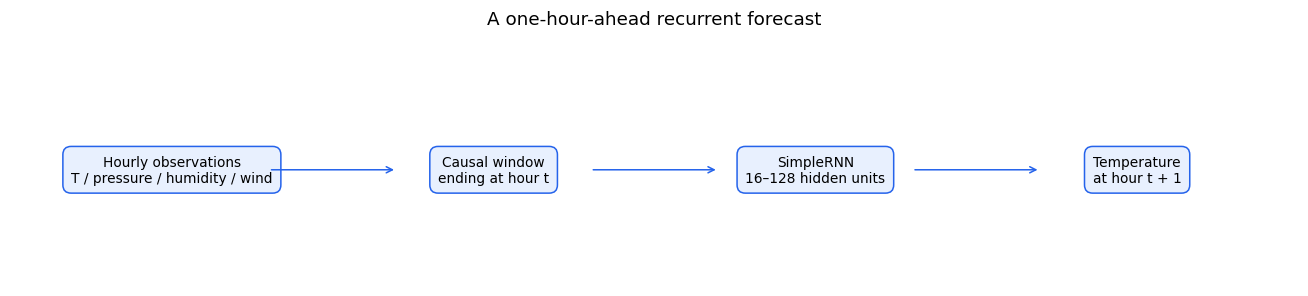

In [2]:
diagram(['Hourly observations\nT / pressure / humidity / wind','Causal window\nending at hour t','SimpleRNN\n16–128 hidden units','Temperature\nat hour t + 1'],'A one-hour-ahead recurrent forecast')

## Clean measurements and chronological partitions

I average the original ten-minute readings within each hour. Invalid wind values (−9999) become zero before resampling. Remaining gaps use past-only forward filling. Because each hourly average is available after that hour ends, predictions are made at the end of the observed hour.

The first 70% of hourly observations are training data, the next 10% are validation data, and the final 20% are test data. Partition membership follows the target timestamp. Windows at a boundary may use earlier observations as context, which would also be available during forecasting.

       0/13568290 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

 8396800/13568290 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

13568290/13568290 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Hourly observations: 70129 Invalid wind values corrected: 18


,partition,first_target,last_target
0,Training,2009-01-05 00:00:00,2014-08-08 09:00:00
1,Validation,2014-08-08 10:00:00,2015-05-27 14:00:00
2,Test,2015-05-27 15:00:00,2017-01-01 00:00:00


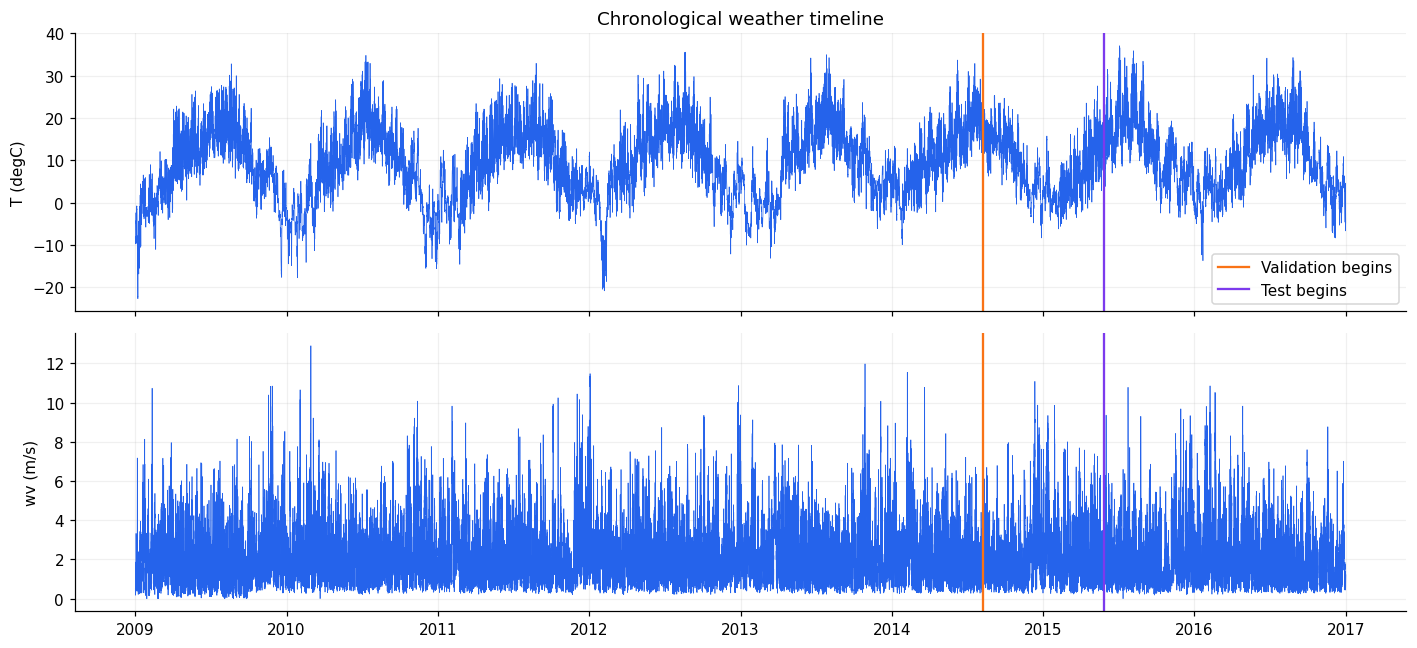

In [3]:
url='https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip'
archive=tf.keras.utils.get_file('jena_climate_2009_2016.csv.zip',origin=url,cache_dir='/tmp/coursework-climate')
with zipfile.ZipFile(archive) as z:
 with z.open('jena_climate_2009_2016.csv') as f:raw=pd.read_csv(f)
raw['Date Time']=pd.to_datetime(raw['Date Time'],format='%d.%m.%Y %H:%M:%S')
features=['T (degC)','p (mbar)','rh (%)','wv (m/s)']
data=raw.set_index('Date Time')[features].sort_index()
invalid_wind=int((data['wv (m/s)']==-9999).sum());data.loc[data['wv (m/s)']==-9999,'wv (m/s)']=0
hourly=data.resample('h').mean().ffill().dropna()
assert hourly.index.is_monotonic_increasing and hourly.index.is_unique
assert (hourly.index.to_series().diff().dropna()==pd.Timedelta(hours=1)).all()
assert np.isfinite(hourly.to_numpy()).all()
n=len(hourly);train_end=int(n*.7);val_end=int(n*.8)
input_scaler=StandardScaler().fit(hourly.iloc[:train_end])
target_mean=float(hourly['T (degC)'].iloc[:train_end].mean());target_std=float(hourly['T (degC)'].iloc[:train_end].std(ddof=0))
X=input_scaler.transform(hourly).astype('float32');temperature=hourly['T (degC)'].to_numpy(dtype='float32');y_scaled=(temperature-target_mean)/target_std
print('Hourly observations:',n,'Invalid wind values corrected:',invalid_wind)
display(pd.DataFrame({'partition':['Training','Validation','Test'],'first_target':[hourly.index[96],hourly.index[train_end],hourly.index[val_end]],'last_target':[hourly.index[train_end-1],hourly.index[val_end-1],hourly.index[-1]]}))
fig,axes=plt.subplots(2,1,figsize=(13,6),sharex=True)
for ax,column in zip(axes,['T (degC)','wv (m/s)']):
 ax.plot(hourly.index,hourly[column],lw=.45,color='#2563eb');ax.axvline(hourly.index[train_end],color='#f97316',label='Validation begins');ax.axvline(hourly.index[val_end],color='#7c3aed',label='Test begins');ax.set_ylabel(column)
axes[0].legend();axes[0].set_title('Chronological weather timeline');plt.tight_layout();plt.show()

## Sequence alignment and a persistence reference

For a target at index k, the inputs are rows k − L through k − 1, and the target is temperature at row k. Thus the most recent input temperature is exactly one hour before the target. A persistence forecast simply repeats that temperature.

Both inputs and targets are standardized using training-period statistics. Evaluation converts predictions back to °C. Sequence length changes the history available, while the validation and test target timestamps stay identical.

Baseline training windows: (49066, 24, 4) Validation windows: (7013, 24, 4)


,timestamp,temperature_celsius,role
0,2014-08-08 04:00:00,13.070000,Input
1,2014-08-08 05:00:00,12.850000,Input
2,2014-08-08 06:00:00,12.788333,Input
3,2014-08-08 07:00:00,13.180000,Input
4,2014-08-08 08:00:00,15.325000,Input
5,2014-08-08 09:00:00,20.358334,Input
6,2014-08-08 10:00:00,22.555000,Next-hour target


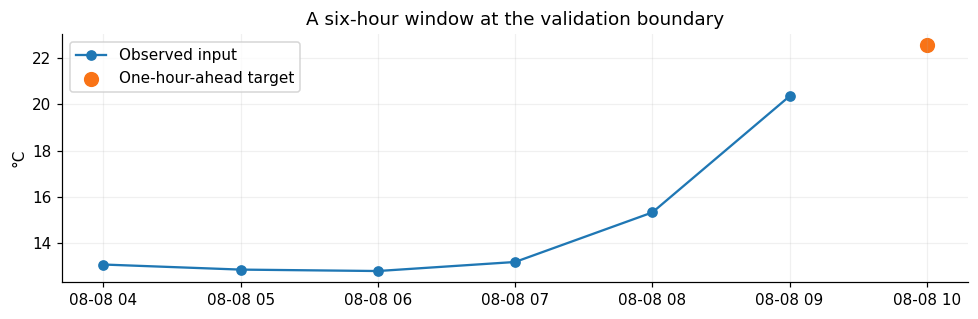

In [4]:
BATCH_SIZE=64;EPOCHS=5
options=tf.data.Options();options.threading.private_threadpool_size=2;options.threading.max_intra_op_parallelism=1
sequence_cache={}
def partition_arrays(length,partition):
 bounds={'train':(length,train_end),'validation':(train_end,val_end),'test':(val_end,n)}
 begin,end=bounds[partition];indices=np.arange(begin,end)
 offsets=np.arange(-length,0)
 inputs=X[indices[:,None]+offsets[None,:]]
 targets=y_scaled[indices]
 assert inputs.shape==(len(indices),length,4)
 assert np.allclose(inputs[:,-1,0],X[indices-1,0])
 return inputs,targets,indices

def dataset(inputs,targets):
 return tf.data.Dataset.from_tensor_slices((inputs,targets[:,None])).batch(BATCH_SIZE).with_options(options).prefetch(1)
def training_data(length):
 if length not in sequence_cache:
  a=partition_arrays(length,'train');b=partition_arrays(length,'validation');sequence_cache[length]=(a,b)
 return sequence_cache[length]
def predict_celsius(model,inputs):
 ds=tf.data.Dataset.from_tensor_slices(inputs).batch(256).with_options(options).prefetch(1)
 return model.predict(ds,verbose=0).reshape(-1)*target_std+target_mean

a,b=training_data(24)
print('Baseline training windows:',a[0].shape,'Validation windows:',b[0].shape)
example_k=train_end
alignment=pd.DataFrame({'timestamp':hourly.index[example_k-6:example_k+1],'temperature_celsius':temperature[example_k-6:example_k+1],'role':['Input']*6+['Next-hour target']});display(alignment)
fig,ax=plt.subplots(figsize=(9,3));ax.plot(alignment.timestamp[:-1],alignment.temperature_celsius[:-1],'o-',label='Observed input');ax.scatter(alignment.timestamp.iloc[-1],alignment.temperature_celsius.iloc[-1],color='#f97316',s=80,label='One-hour-ahead target');ax.set(title='A six-hour window at the validation boundary',ylabel='°C');ax.legend();plt.tight_layout();plt.show()

## Baseline and validation-selected training

Each configuration trains for five epochs with Adam, batch size 64, and chronological batch order. I save the lowest-validation-loss weights within that fixed budget, then compare configurations by validation MAE. A common seed controls initialization; one run per configuration does not measure variability across seeds. Training time includes graph tracing and is only a descriptive measurement.

I0000 00:00:1791808253.678087      17 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791808253.684945      17 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Epoch 1/5


I0000 00:00:1791808257.896292      57 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


767/767 - 7s - 9ms/step - loss: 0.0770 - mae: 0.1710 - val_loss: 0.0152 - val_mae: 0.0968


Epoch 2/5


...

767/767 - 3s - 4ms/step - loss: 0.0074 - mae: 0.0623 - val_loss: 0.0080 - val_mae: 0.0699


Epoch 5/5


767/767 - 3s - 4ms/step - loss: 0.0066 - mae: 0.0588 - val_loss: 0.0070 - val_mae: 0.0643


Finished history 24, units 32; selected epoch 5


,history_hours,hidden_units,parameters,selected_epoch,validation_mae,validation_mse,persistence_mae,training_seconds
0,24,32,1217,5,0.556077,0.521488,0.623595,20.09059


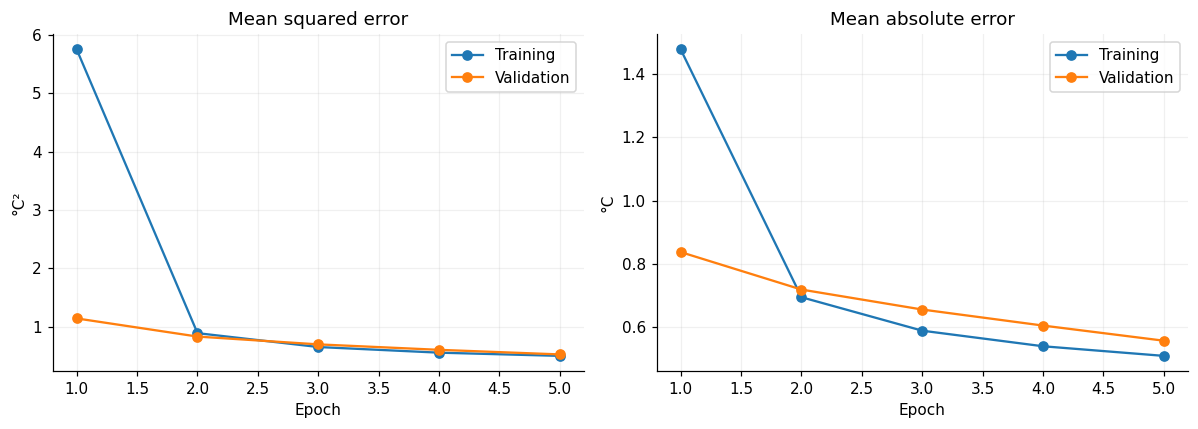

In [5]:
models_by_setting={};histories={};timings={}
def fit_configuration(length,units):
 key=(length,units)
 if key in models_by_setting:return models_by_setting[key]
 tf.keras.utils.set_random_seed(SEED)
 model=tf.keras.Sequential([tf.keras.Input(shape=(length,4)),tf.keras.layers.SimpleRNN(units),tf.keras.layers.Dense(1)])
 model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=.001),loss='mse',metrics=['mae'])
 class BestWeights(tf.keras.callbacks.Callback):
  def on_train_begin(self,logs=None):self.loss=float('inf');self.weights=None;self.epoch=None
  def on_epoch_end(self,epoch,logs=None):
   if logs['val_loss']<self.loss:self.loss=logs['val_loss'];self.weights=self.model.get_weights();self.epoch=epoch+1
 callback=BestWeights();a,b=training_data(length)
 start=time.perf_counter();history=model.fit(dataset(a[0],a[1]),validation_data=dataset(b[0],b[1]),epochs=EPOCHS,callbacks=[callback],verbose=2);timings[key]=time.perf_counter()-start
 model.set_weights(callback.weights);model.best_epoch=callback.epoch
 models_by_setting[key]=model;histories[key]=history.history
 print(f'Finished history {length}, units {units}; selected epoch {model.best_epoch}',flush=True)
 return model

def validation_row(length,units):
 model=fit_configuration(length,units);_,b=training_data(length);pred=predict_celsius(model,b[0]);actual=temperature[b[2]]
 persistence=temperature[b[2]-1]
 return {'history_hours':length,'hidden_units':units,'parameters':model.count_params(),'selected_epoch':model.best_epoch,'validation_mae':mean_absolute_error(actual,pred),'validation_mse':mean_squared_error(actual,pred),'persistence_mae':mean_absolute_error(actual,persistence),'training_seconds':timings[(length,units)]}
baseline_model=fit_configuration(24,32);baseline_validation=validation_row(24,32);display(pd.DataFrame([baseline_validation]))
h=histories[(24,32)];fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,metric,title in [(axes[0],'loss','Mean squared error'),(axes[1],'mae','Mean absolute error')]:
 for prefix,label in [('', 'Training'),('val_', 'Validation')]:ax.plot(np.arange(1,EPOCHS+1),np.array(h[prefix+metric])*(target_std**2 if metric=='loss' else target_std),marker='o',label=label)
 ax.set(title=title,xlabel='Epoch',ylabel='°C²' if metric=='loss' else '°C');ax.legend()
plt.tight_layout();plt.show()

## How much history helps?

I compare 6, 12, 24, 48, and 96 hourly observations with 32 hidden units. All models are evaluated against the same validation targets. Longer input windows do not automatically improve forecasting, especially under a short training budget.

Epoch 1/5


767/767 - 5s - 7ms/step - loss: 0.0809 - mae: 0.1717 - val_loss: 0.0153 - val_mae: 0.0968


Epoch 2/5


767/767 - 2s - 3ms/step - loss: 0.0115 - mae: 0.0789 - val_loss: 0.0131 - val_mae: 0.0917


Epoch 3/5


...

766/766 - 6s - 7ms/step - loss: 0.0074 - mae: 0.0625 - val_loss: 0.0081 - val_mae: 0.0701


Epoch 5/5


766/766 - 6s - 7ms/step - loss: 0.0067 - mae: 0.0589 - val_loss: 0.0070 - val_mae: 0.0643


Finished history 96, units 32; selected epoch 5


,history_hours,hidden_units,parameters,selected_epoch,validation_mae,validation_mse,persistence_mae,training_seconds
0,6,32,1217,5,0.602389,0.597376,0.623595,14.908453
1,12,32,1217,5,0.518453,0.470033,0.623595,17.160108
2,24,32,1217,5,0.556077,0.521488,0.623595,20.090590
3,48,32,1217,5,0.560807,0.527288,0.623595,21.960161
4,96,32,1217,5,0.556259,0.521854,0.623595,31.519056


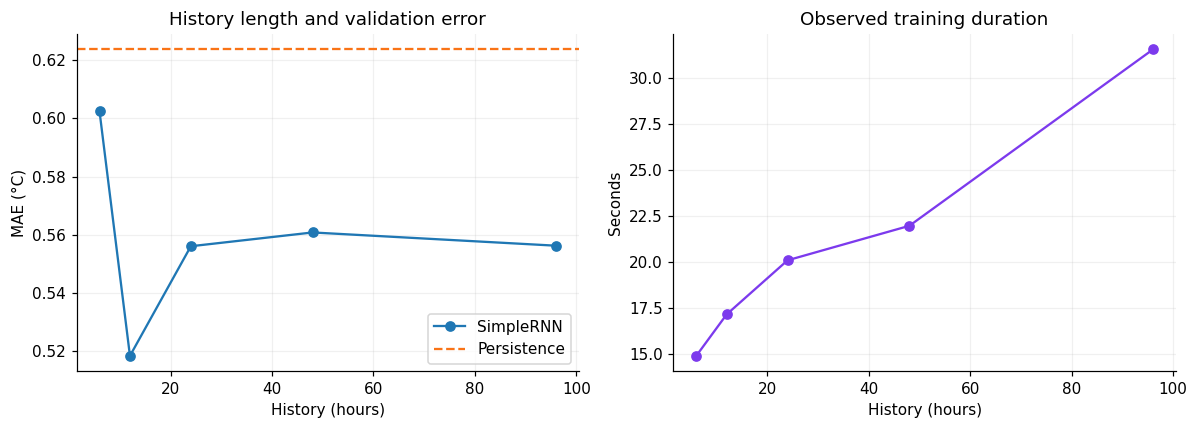

In [6]:
sequence_results=pd.DataFrame([validation_row(length,32) for length in [6,12,24,48,96]])
display(sequence_results)
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(sequence_results.history_hours,sequence_results.validation_mae,'o-',label='SimpleRNN');axes[0].axhline(sequence_results.persistence_mae.iloc[0],color='#f97316',ls='--',label='Persistence');axes[0].set(title='History length and validation error',xlabel='History (hours)',ylabel='MAE (°C)');axes[0].legend()
axes[1].plot(sequence_results.history_hours,sequence_results.training_seconds,'o-',color='#7c3aed');axes[1].set(title='Observed training duration',xlabel='History (hours)',ylabel='Seconds')
plt.tight_layout();plt.show()

## Backpropagation through time

I reuse the trained 12-, 48-, and 96-hour models. For the same 64 validation target timestamps, I reconstruct each recurrence with its learned weights and verify that manual predictions match the Keras forward pass. I differentiate standardized-target MSE with respect to every hidden state.

The earliest-to-final gradient ratio describes these batches and checkpoints. It can indicate attenuation or amplification, but does not by itself explain forecast quality. A longer sequence is not guaranteed to produce a smaller ratio.

,history_hours,earliest_gradient,final_gradient,earliest_to_final_ratio
0,12,1.822830e-05,0.000496,3.675748e-02
1,48,2.637701e-08,0.000500,5.279327e-05
2,96,2.330580e-11,0.000497,4.685247e-08


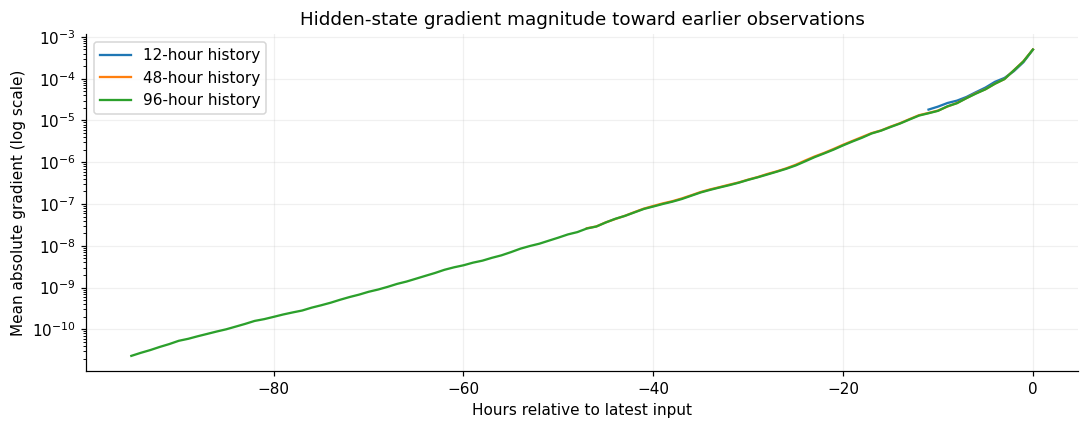

In [7]:
gradient_rows=[];gradient_profiles={}
for length in [12,48,96]:
 model=models_by_setting[(length,32)];_,b=training_data(length)
 xb=tf.constant(b[0][:64]);yb=tf.constant(b[1][:64,None]);rnn=model.layers[0];dense=model.layers[1]
 kernel,recurrent,bias=[tf.constant(w) for w in rnn.get_weights()];dk,db=[tf.constant(w) for w in dense.get_weights()]
 with tf.GradientTape() as tape:
  hidden=tf.zeros((len(xb),32));states=[]
  for t in range(length):
   hidden=tf.math.tanh(xb[:,t]@kernel+hidden@recurrent+bias);tape.watch(hidden);states.append(hidden)
  manual=hidden@dk+db;loss=tf.reduce_mean(tf.square(yb-manual))
 gradients=tape.gradient(loss,states);assert all(g is not None for g in gradients)
 np.testing.assert_allclose(manual.numpy(),model(xb,training=False).numpy(),atol=1e-5,rtol=1e-5)
 magnitudes=np.array([tf.reduce_mean(tf.abs(g)).numpy() for g in gradients]);assert np.isfinite(magnitudes).all()
 gradient_profiles[length]=magnitudes
 gradient_rows.append({'history_hours':length,'earliest_gradient':float(magnitudes[0]),'final_gradient':float(magnitudes[-1]),'earliest_to_final_ratio':float(magnitudes[0]/magnitudes[-1])})
gradient_results=pd.DataFrame(gradient_rows);display(gradient_results)
fig,ax=plt.subplots(figsize=(10,4))
for length,magnitudes in gradient_profiles.items():ax.semilogy(np.arange(-length+1,1),np.maximum(magnitudes,1e-20),label=f'{length}-hour history')
ax.set(title='Hidden-state gradient magnitude toward earlier observations',xlabel='Hours relative to latest input',ylabel='Mean absolute gradient (log scale)');ax.legend();plt.tight_layout();plt.show()

## Hidden-state capacity

I compare 16, 32, 64, and 128 hidden units with a fixed 24-hour window. For four inputs and one output, the parameter count is H(H + 4 + 1) + H + 1. The recurrent weight matrix makes model size grow roughly quadratically in H.

Epoch 1/5


767/767 - 6s - 8ms/step - loss: 0.0718 - mae: 0.1737 - val_loss: 0.0138 - val_mae: 0.0885


Epoch 2/5


767/767 - 3s - 4ms/step - loss: 0.0145 - mae: 0.0863 - val_loss: 0.0092 - val_mae: 0.0714


Epoch 3/5


...

767/767 - 3s - 4ms/step - loss: 0.0061 - mae: 0.0565 - val_loss: 0.0052 - val_mae: 0.0526


Epoch 5/5


767/767 - 3s - 4ms/step - loss: 0.0058 - mae: 0.0548 - val_loss: 0.0051 - val_mae: 0.0524


Finished history 24, units 128; selected epoch 5


,history_hours,hidden_units,parameters,selected_epoch,validation_mae,validation_mse,persistence_mae,training_seconds
0,24,16,353,5,0.527769,0.498139,0.623595,19.220573
1,24,32,1217,5,0.556077,0.521488,0.623595,20.090590
2,24,64,4481,5,0.461528,0.396191,0.623595,19.400844
3,24,128,17153,5,0.452654,0.384071,0.623595,19.330759


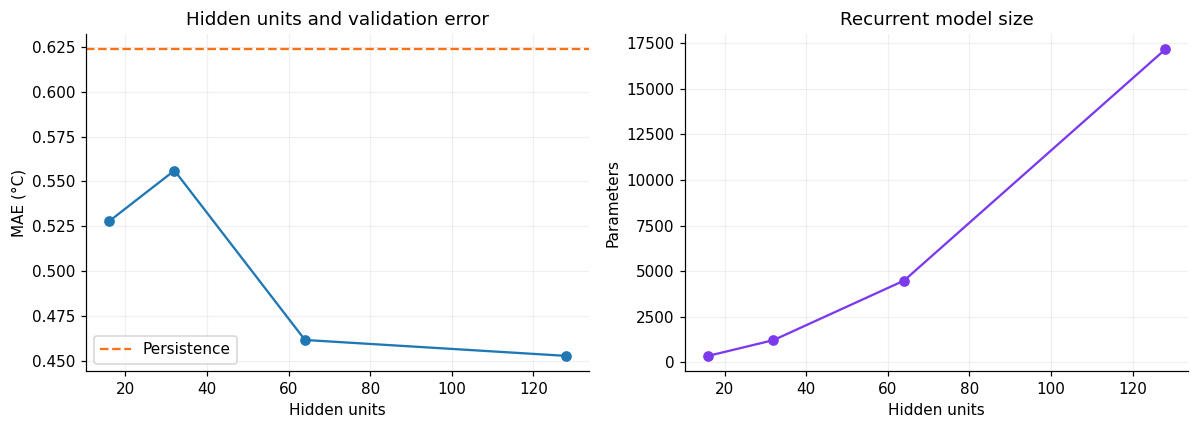

In [8]:
hidden_results=pd.DataFrame([validation_row(24,units) for units in [16,32,64,128]])
assert all(row.parameters==row.hidden_units*(row.hidden_units+6)+1 for row in hidden_results.itertuples())
display(hidden_results)
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(hidden_results.hidden_units,hidden_results.validation_mae,'o-');axes[0].axhline(hidden_results.persistence_mae.iloc[0],color='#f97316',ls='--',label='Persistence');axes[0].set(title='Hidden units and validation error',xlabel='Hidden units',ylabel='MAE (°C)');axes[0].legend()
axes[1].plot(hidden_results.hidden_units,hidden_results.parameters,'o-',color='#7c3aed');axes[1].set(title='Recurrent model size',xlabel='Hidden units',ylabel='Parameters')
plt.tight_layout();plt.show()

## Final selection and held-out evaluation

The final configuration combines the best validation history from the history sweep and the best validation capacity from the fixed-24-hour sweep. This is a sequential search, not a complete joint grid. If the pair was not previously trained, it receives the same five-epoch budget and validation checkpoint selection. I do not refit on validation data.

Only now do I evaluate the baseline, selected model, and persistence on the common test target timestamps. Test errors do not determine the chosen configuration.

Epoch 1/5


767/767 - 6s - 8ms/step - loss: 0.0322 - mae: 0.1151 - val_loss: 0.0091 - val_mae: 0.0695


Epoch 2/5


767/767 - 3s - 4ms/step - loss: 0.0092 - mae: 0.0712 - val_loss: 0.0072 - val_mae: 0.0632


Epoch 3/5


...

767/767 - 3s - 4ms/step - loss: 0.0065 - mae: 0.0587 - val_loss: 0.0059 - val_mae: 0.0576


Epoch 5/5


767/767 - 3s - 4ms/step - loss: 0.0062 - mae: 0.0571 - val_loss: 0.0060 - val_mae: 0.0586


Finished history 12, units 128; selected epoch 4


,model,history_hours,hidden_units,parameters,test_mae,test_mse
0,Persistence,1,0,0,0.681332,0.898558
1,Baseline SimpleRNN,24,32,1217,0.555623,0.532743
2,Selected SimpleRNN,12,128,17153,0.508608,0.459207


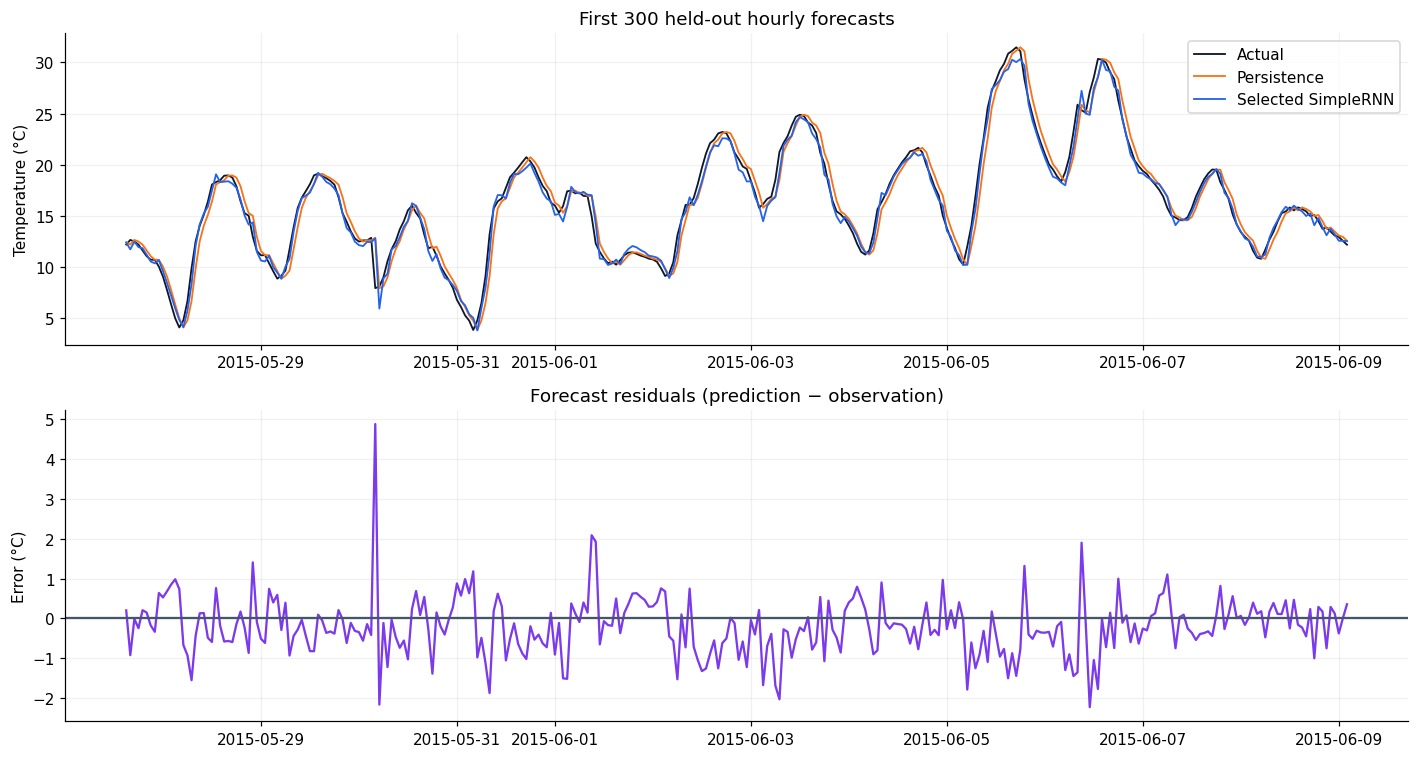

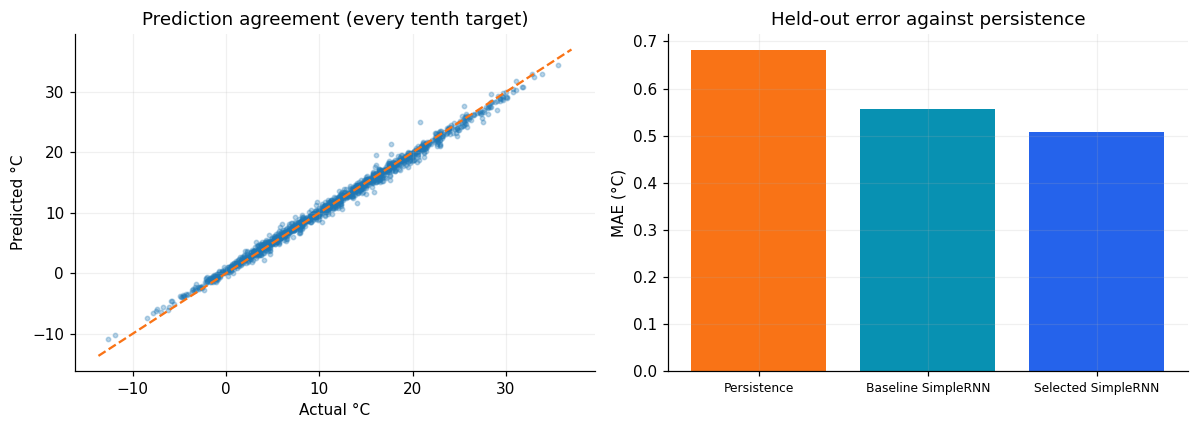

In [9]:
best_length=int(sequence_results.loc[sequence_results.validation_mae.idxmin(),'history_hours'])
best_units=int(hidden_results.loc[hidden_results.validation_mae.idxmin(),'hidden_units'])
final_model=fit_configuration(best_length,best_units);final_validation=validation_row(best_length,best_units)
xb,_,indices=partition_arrays(24,'test');xf,_,final_indices=partition_arrays(best_length,'test');assert np.array_equal(indices,final_indices)
actual=temperature[indices];persistence=temperature[indices-1]
baseline_predictions=predict_celsius(baseline_model,xb);final_predictions=predict_celsius(final_model,xf)
test_rows=[]
for name,pred,model,length,units in [('Persistence',persistence,None,1,0),('Baseline SimpleRNN',baseline_predictions,baseline_model,24,32),('Selected SimpleRNN',final_predictions,final_model,best_length,best_units)]:
 test_rows.append({'model':name,'history_hours':length,'hidden_units':units,'parameters':model.count_params() if model else 0,'test_mae':mean_absolute_error(actual,pred),'test_mse':mean_squared_error(actual,pred)})
test_results=pd.DataFrame(test_rows);display(test_results)
fig,axes=plt.subplots(2,1,figsize=(13,7))
stamps=hourly.index[indices[:300]]
for pred,label,color in [(actual,'Actual','#0f172a'),(persistence,'Persistence','#f97316'),(final_predictions,'Selected SimpleRNN','#2563eb')]:axes[0].plot(stamps,pred[:300],label=label,color=color,lw=1.2)
axes[0].set(title='First 300 held-out hourly forecasts',ylabel='Temperature (°C)');axes[0].legend()
axes[1].plot(stamps,(final_predictions-actual)[:300],color='#7c3aed');axes[1].axhline(0,color='#475569');axes[1].set(title='Forecast residuals (prediction − observation)',ylabel='Error (°C)')
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].scatter(actual[::10],final_predictions[::10],s=8,alpha=.3);limits=[min(actual.min(),final_predictions.min()),max(actual.max(),final_predictions.max())];axes[0].plot(limits,limits,'--',color='#f97316');axes[0].set(title='Prediction agreement (every tenth target)',xlabel='Actual °C',ylabel='Predicted °C')
axes[1].bar(test_results.model,test_results.test_mae,color=['#f97316','#0891b2','#2563eb']);axes[1].set(title='Held-out error against persistence',ylabel='MAE (°C)');axes[1].tick_params(axis='x',labelsize=8)
plt.tight_layout();plt.show()
result={'hourly_observations':n,'train_end':train_end,'validation_end':val_end,'test_targets':len(indices),'invalid_wind_values':invalid_wind,'epochs_per_configuration':EPOCHS,'final_history_hours':best_length,'final_hidden_units':best_units,'final_validation':final_validation,'test_results':test_results.to_dict('records'),'gradient_results':gradient_results.to_dict('records'),'test_first_target':str(hourly.index[indices[0]]),'test_last_target':str(hourly.index[indices[-1]])}
Path('results.json').write_text(json.dumps(result,indent=2));sequence_results.to_csv('history_length_results.csv',index=False);hidden_results.to_csv('hidden_capacity_results.csv',index=False);gradient_results.to_csv('gradient_results.csv',index=False);test_results.to_csv('test_results.csv',index=False)

## What I learned

Correct target alignment and chronological selection matter as much as the recurrent architecture. Scaling the target helps optimization while °C metrics keep results interpretable. A strong persistence reference is essential for one-hour weather forecasting; a trained network need not beat it. Extra history or hidden units can add cost without helping within a five-epoch budget. Gradient profiles describe learned dynamics but do not establish why one configuration forecasts better.

Reference: [TensorFlow time-series forecasting and Jena Climate data](https://www.tensorflow.org/tutorials/structured_data/time_series).

## Measured findings

The selected **12-hour, 128-unit** model achieved test MAE **0.5086 °C** versus persistence MAE **0.6813 °C**. The selected RNN improved on persistence in this run.